In [1]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [2]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle

In [3]:
!kaggle --version

Kaggle CLI 2.0.2


In [4]:
!kaggle datasets download -d johnsmith88/heart-disease-dataset

Dataset URL: https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset
License(s): unknown
100% 6.18k/6.18k [00:00<00:00, 15.7MB/s]



In [5]:
import zipfile
import glob

zip_file = glob.glob("*.zip")[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("heart_disease_data")

!ls heart_disease_data

heart.csv


In [6]:
import pandas as pd

df = pd.read_csv("heart_disease_data/heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [7]:

print("Shape of the dataset:", df.shape)

df.info()

print("\nMissing values:")
print(df.isnull().sum())


Shape of the dataset: (1025, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          

Exploratory Data Analysis (EDA)

In [8]:
df.shape

(1025, 14)

In [9]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


Checking the Distribution of Heart Disease

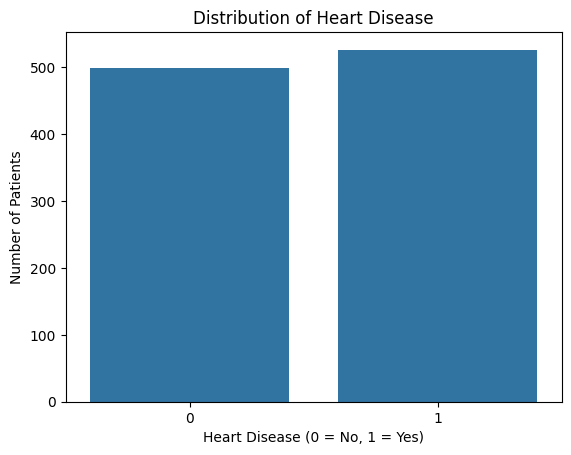

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='target', data=df)

plt.title('Distribution of Heart Disease')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.show()

In [11]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

Correlation Analysis

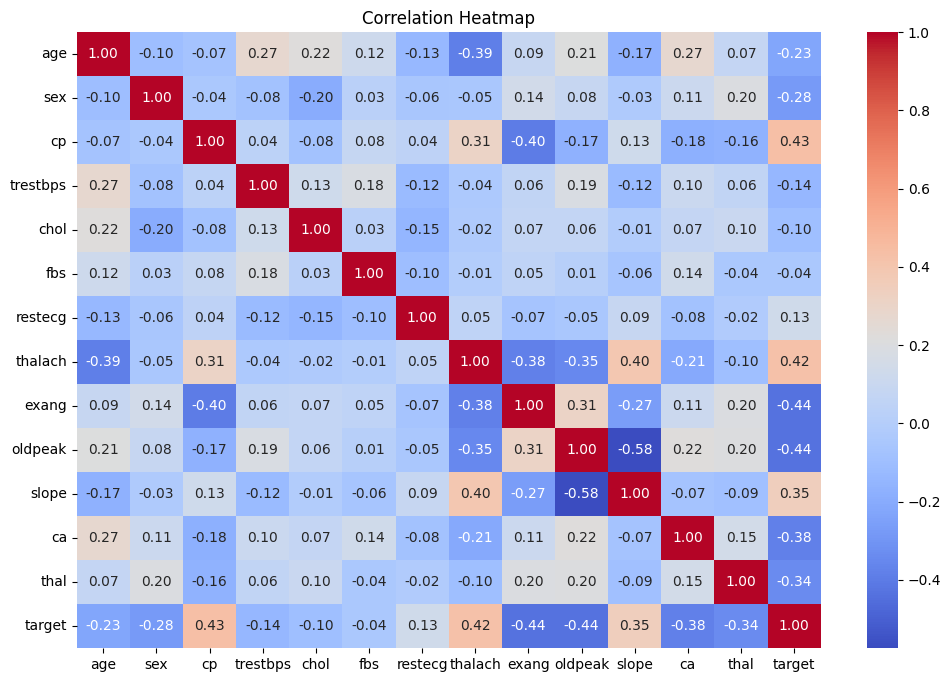

In [12]:
plt.figure(figsize=(12, 8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

Separating Features and Target Variable

In [13]:
X = df.drop('target', axis=1)
y = df['target']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (1025, 13)
Shape of y: (1025,)


Splitting the Dataset into Training and Testing Sets

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (820, 13)
Testing data: (205, 13)


Feature Scaling

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Building the Classification Models

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

Training the Models

In [17]:
models["Logistic Regression"].fit(X_train_scaled, y_train)
models["Decision Tree"].fit(X_train, y_train)
models["Random Forest"].fit(X_train, y_train)
models["SVM"].fit(X_train_scaled, y_train)

print("All four models have been trained successfully.")

All four models have been trained successfully.


Evaluating the Models

In [18]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

results = []

for name, model in models.items():
    if name in ["Logistic Regression", "SVM"]:
        X_test_model = X_test_scaled
    else:
        X_test_model = X_test

    y_pred = model.predict(X_test_model)
    y_prob = model.predict_proba(X_test_model)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.810,0.762,0.914,0.831,0.930
1,Decision Tree,0.985,1.000,0.971,0.986,0.986
2,Random Forest,1.000,1.000,1.000,1.000,1.000
3,SVM,0.927,0.917,0.943,0.930,0.977


Model Evaluation Using Specificity

In [19]:
from sklearn.metrics import confusion_matrix

for name, model in models.items():
    if name in ["Logistic Regression", "SVM"]:
        X_test_model = X_test_scaled
    else:
        X_test_model = X_test

    y_pred = model.predict(X_test_model)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    results_df.loc[results_df["Model"] == name, "Specificity"] = specificity

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Specificity
0,Logistic Regression,0.810,0.762,0.914,0.831,0.930,0.70
1,Decision Tree,0.985,1.000,0.971,0.986,0.986,1.00
2,Random Forest,1.000,1.000,1.000,1.000,1.000,1.00
3,SVM,0.927,0.917,0.943,0.930,0.977,0.91


Comparing Model Performance

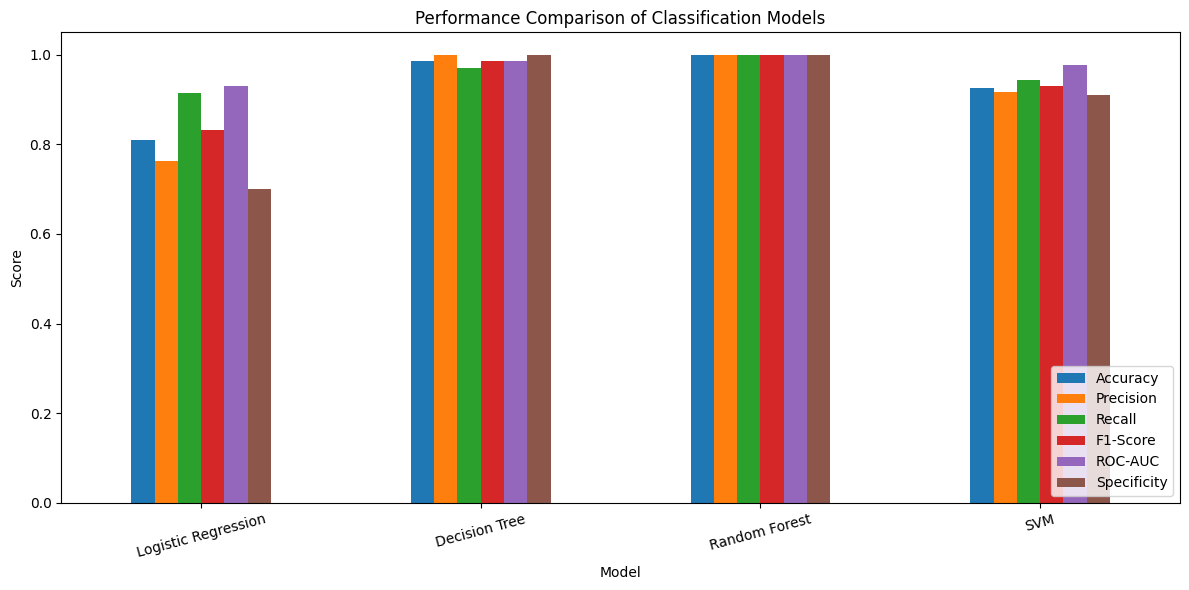

In [20]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "Specificity"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Confusion Matrix

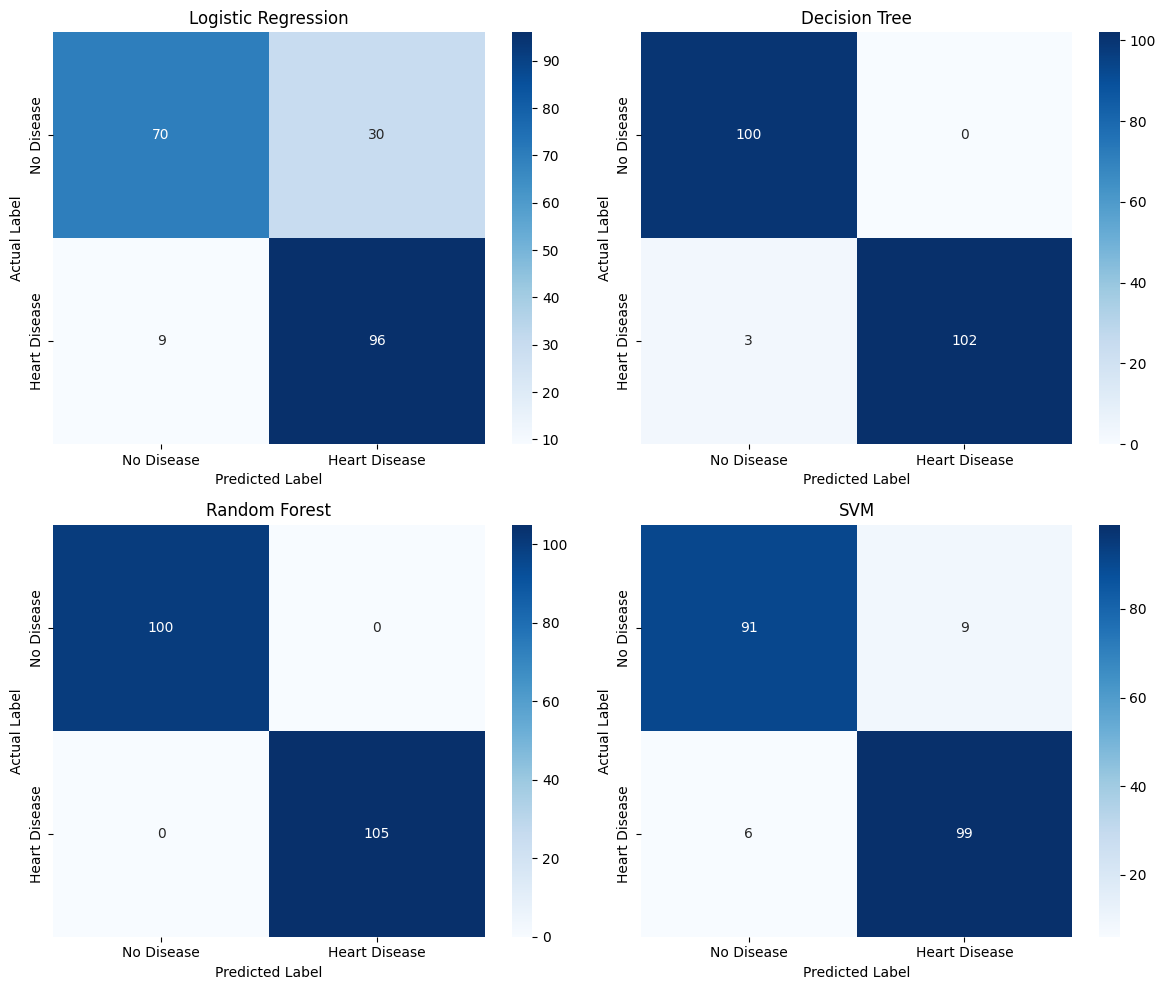

In [21]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, model) in zip(axes.flatten(), models.items()):
    if name in ["Logistic Regression", "SVM"]:
        X_test_model = X_test_scaled
    else:
        X_test_model = X_test

    y_pred = model.predict(X_test_model)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Disease", "Heart Disease"],
        yticklabels=["No Disease", "Heart Disease"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

Classification Report

In [22]:
from sklearn.metrics import classification_report

for name, model in models.items():
    if name in ["Logistic Regression", "SVM"]:
        X_test_model = X_test_scaled
    else:
        X_test_model = X_test

    y_pred = model.predict(X_test_model)

    print("\nModel:", name)
    print(classification_report(
        y_test, y_pred,
        target_names=["No Heart Disease", "Heart Disease"],
        zero_division=0
    ))


Model: Logistic Regression
                  precision    recall  f1-score   support

No Heart Disease       0.89      0.70      0.78       100
   Heart Disease       0.76      0.91      0.83       105

        accuracy                           0.81       205
       macro avg       0.82      0.81      0.81       205
    weighted avg       0.82      0.81      0.81       205


Model: Decision Tree
                  precision    recall  f1-score   support

No Heart Disease       0.97      1.00      0.99       100
   Heart Disease       1.00      0.97      0.99       105

        accuracy                           0.99       205
       macro avg       0.99      0.99      0.99       205
    weighted avg       0.99      0.99      0.99       205


Model: Random Forest
                  precision    recall  f1-score   support

No Heart Disease       1.00      1.00      1.00       100
   Heart Disease       1.00      1.00      1.00       105

        accuracy                           1.00   

ROC Curve Analysis

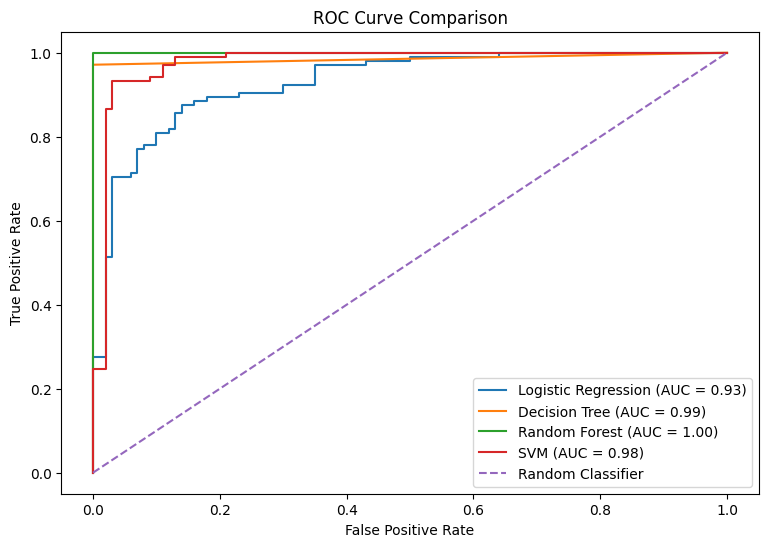

In [23]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 6))

for name, model in models.items():
    if name in ["Logistic Regression", "SVM"]:
        X_test_model = X_test_scaled
    else:
        X_test_model = X_test

    y_prob = model.predict_proba(X_test_model)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

Selecting the Best Performing Model

In [24]:
results_df = results_df.sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Specificity
0,Random Forest,1.000,1.000,1.000,1.000,1.000,1.00
1,Decision Tree,0.985,1.000,0.971,0.986,0.986,1.00
2,SVM,0.927,0.917,0.943,0.930,0.977,0.91
3,Logistic Regression,0.810,0.762,0.914,0.831,0.930,0.70


Heart Disease Prediction Using User Input

In [25]:
import pandas as pd

age = int(input("Enter Age: "))
sex = int(input("Enter Sex (1 = Male, 0 = Female): "))
cp = int(input("Enter Chest Pain Type (cp): "))
trestbps = float(input("Enter Resting Blood Pressure: "))
chol = float(input("Enter Cholesterol Level: "))
fbs = int(input("Enter Fasting Blood Sugar (0 or 1): "))
restecg = int(input("Enter Resting ECG (restecg): "))
thalach = float(input("Enter Maximum Heart Rate: "))
exang = int(input("Enter Exercise-Induced Angina (0 or 1): "))
oldpeak = float(input("Enter ST Depression (oldpeak): "))
slope = int(input("Enter ST Slope: "))
ca = int(input("Enter Number of Major Vessels (ca): "))
thal = int(input("Enter Thalassemia (thal): "))

user_input = pd.DataFrame([{
    'age': age,
    'sex': sex,
    'cp': cp,
    'trestbps': trestbps,
    'chol': chol,
    'fbs': fbs,
    'restecg': restecg,
    'thalach': thalach,
    'exang': exang,
    'oldpeak': oldpeak,
    'slope': slope,
    'ca': ca,
    'thal': thal
}])

user_input = user_input[X.columns]

prediction = models["Random Forest"].predict(user_input)[0]
probability = models["Random Forest"].predict_proba(user_input)[0]

print("\nPrediction Result:")

if prediction == 1:
    print("The model predicts: Heart disease detected.")
else:
    print("The model predicts: No heart disease detected.")

print(f"Estimated probability for class 0: {probability[0] * 100:.2f}%")
print(f"Estimated probability for class 1: {probability[1] * 100:.2f}%")

Enter Age: 50
Enter Sex (1 = Male, 0 = Female): 1
Enter Chest Pain Type (cp): 0
Enter Resting Blood Pressure: 125
Enter Cholesterol Level: 212
Enter Fasting Blood Sugar (0 or 1): 0
Enter Resting ECG (restecg): 1
Enter Maximum Heart Rate: 168
Enter Exercise-Induced Angina (0 or 1): 0
Enter ST Depression (oldpeak): 0.5
Enter ST Slope: 2
Enter Number of Major Vessels (ca): 0
Enter Thalassemia (thal): 2

Prediction Result:
The model predicts: Heart disease detected.
Estimated probability for class 0: 3.00%
Estimated probability for class 1: 97.00%


In [26]:
best_model_name = results_df.loc[0, "Model"]
print("Model with the highest ROC-AUC score:", best_model_name)

Model with the highest ROC-AUC score: Random Forest


Conclusion

In this project, We developed and compared four machine learning classification algorithms to predict the presence of heart disease. The models used were Logistic Regression, Decision Tree, Random Forest, and Support Vector Machine (SVM).

The models were evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and specificity. Based on the evaluation results, Random Forest achieved the highest ROC-AUC score among the four models.

This project helped us understand how machine learning classification algorithms can be applied to healthcare data and how different evaluation metrics can be used to compare model performance.



In [27]:
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Specificity
0,Random Forest,1.000,1.000,1.000,1.000,1.000,1.00
1,Decision Tree,0.985,1.000,0.971,0.986,0.986,1.00
2,SVM,0.927,0.917,0.943,0.930,0.977,0.91
3,Logistic Regression,0.810,0.762,0.914,0.831,0.930,0.70
